In [3]:


import pandas as pd
import requests
from io import BytesIO

url = "https://raw.githubusercontent.com/r-spacex/SpaceX-API/master/README.md"

response = requests.get(url, timeout=30)
print("GitHub connection status:", response.status_code)

if response.ok:
    print("Connection to GitHub works.")
else:
    print("GitHub request failed. Status:", response.status_code)



GitHub connection status: 200
Connection to GitHub works.


In [4]:

# Extract useful launch information

data = []

for launch in launches:
    cores = launch.get("cores", [])

    # Keep launches with a recorded first-stage landing outcome
    for core in cores:
        if core.get("landing_success") is not None:
            data.append({
                "FlightNumber": launch.get("flight_number"),
                "Date": launch.get("date_utc"),
                "BoosterVersion": core.get("core"),
                "LaunchSite": None,
                "PayloadMass": None,
                "Orbit": None,
                "LandingSuccess": core.get("landing_success"),
                "LandingType": core.get("landing_type"),
                "LaunchSuccess": launch.get("success")
            })

df = pd.DataFrame(data)

# Convert date to datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce", utc=True)

print("Filtered dataset shape:", df.shape)
print("\nLanding outcome counts:")
display(df["LandingSuccess"].value_counts(dropna=False).rename_axis("LandingSuccess").to_frame("Count"))

print("\nPreview:")
display(df.head(10))


NameError: name 'launches' is not defined

In [6]:

import pandas as pd

# Try the IBM capstone dataset sources
urls = [
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv",
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/dataset_part_2.csv"
]

df = None

for url in urls:
    try:
        candidate = pd.read_csv(url)
        if not candidate.empty:
            df = candidate
            print("Dataset loaded successfully from:", url)
            break
    except Exception as e:
        print("Source unavailable:", str(e)[:150])

if df is not None:
    print("Dataset shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())
    display(df.head())
else:
    print("Neither source worked. Send me this output.")



Dataset loaded successfully from: https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv
Dataset shape: (90, 18)

Columns:
['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Class']


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


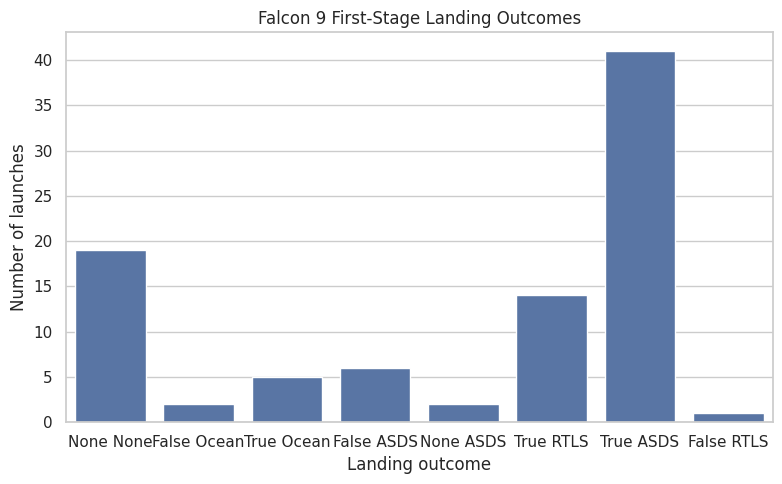

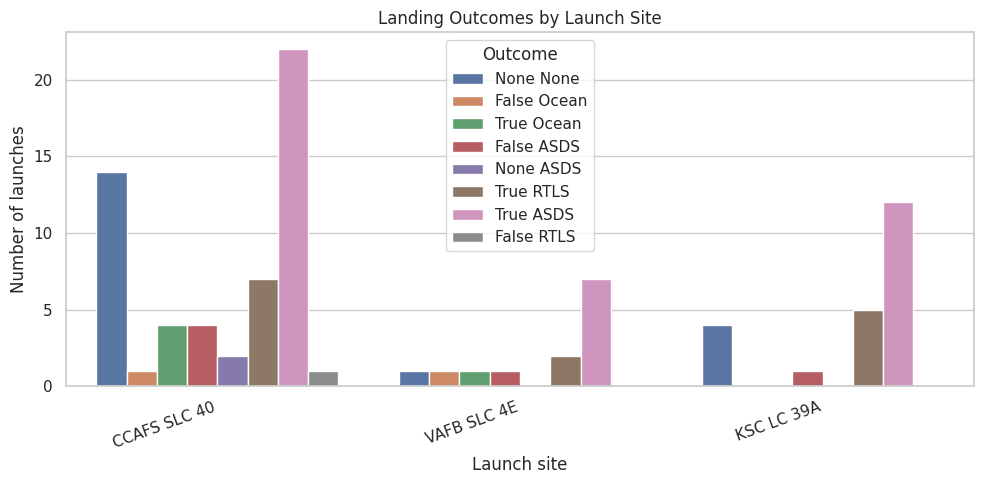

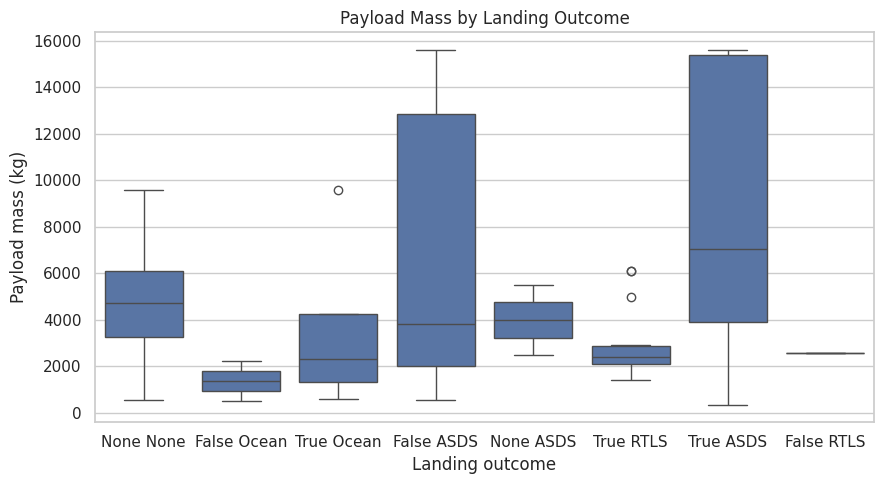

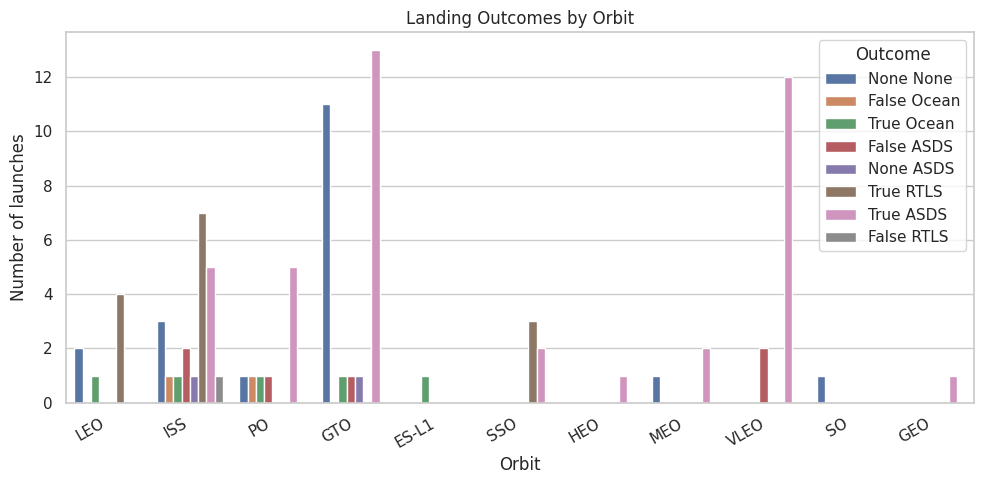

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Prepare the data
df["PayloadMass"] = pd.to_numeric(df["PayloadMass"], errors="coerce")
df["FlightNumber"] = pd.to_numeric(df["FlightNumber"], errors="coerce")

sns.set_theme(style="whitegrid")

# Chart 1: Launch outcomes
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Outcome")
plt.title("Falcon 9 First-Stage Landing Outcomes")
plt.xlabel("Landing outcome")
plt.ylabel("Number of launches")
plt.tight_layout()
plt.show()

# Chart 2: Launch outcomes by launch site
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="LaunchSite", hue="Outcome")
plt.title("Landing Outcomes by Launch Site")
plt.xlabel("Launch site")
plt.ylabel("Number of launches")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Chart 3: Payload mass vs landing outcome
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Outcome", y="PayloadMass")
plt.title("Payload Mass by Landing Outcome")
plt.xlabel("Landing outcome")
plt.ylabel("Payload mass (kg)")
plt.tight_layout()
plt.show()

# Chart 4: Landing outcome by orbit
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Orbit", hue="Outcome")
plt.title("Landing Outcomes by Orbit")
plt.xlabel("Orbit")
plt.ylabel("Number of launches")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


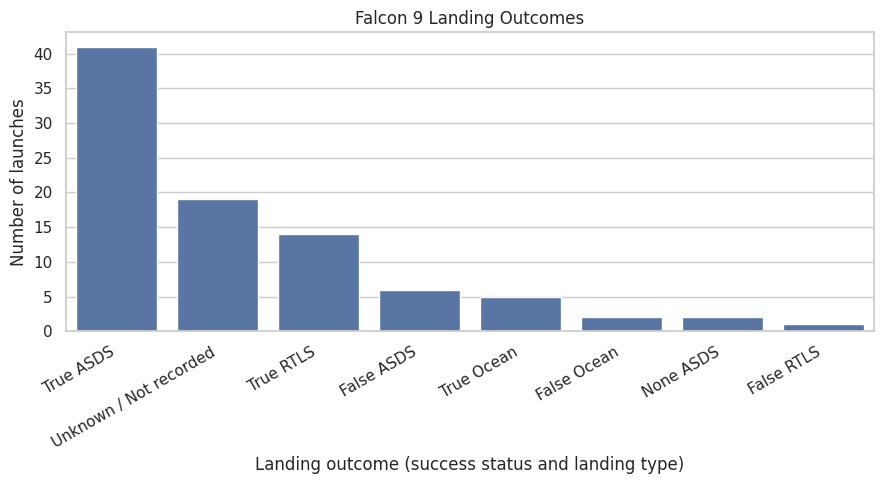

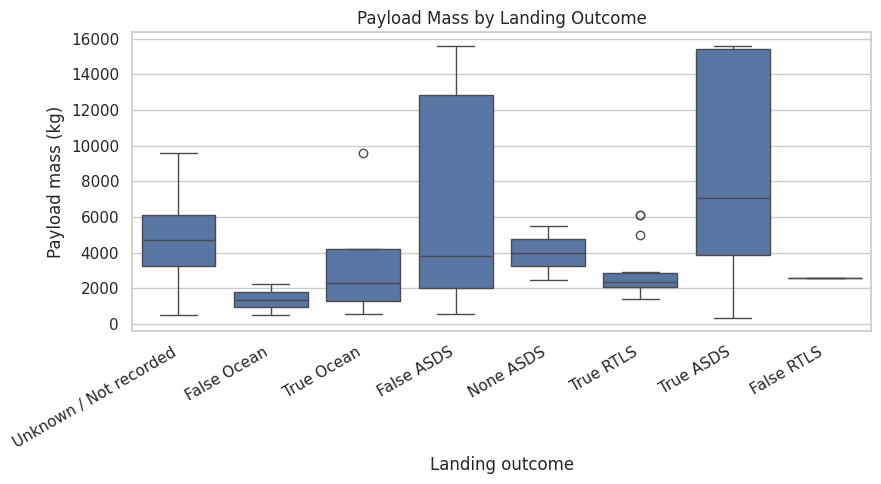

In [9]:

# Create a clean landing outcome label
df["LandingOutcome"] = df["Outcome"].astype(str).str.strip()

df["LandingOutcome"] = df["LandingOutcome"].replace({
    "None None": "Unknown / Not recorded",
    "None": "Unknown / Not recorded"
})

# Plot clean landing outcome counts
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="LandingOutcome",
    order=df["LandingOutcome"].value_counts().index
)
plt.title("Falcon 9 Landing Outcomes")
plt.xlabel("Landing outcome (success status and landing type)")
plt.ylabel("Number of launches")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Plot payload mass by launch outcome
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="LandingOutcome", y="PayloadMass")
plt.title("Payload Mass by Landing Outcome")
plt.xlabel("Landing outcome")
plt.ylabel("Payload mass (kg)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


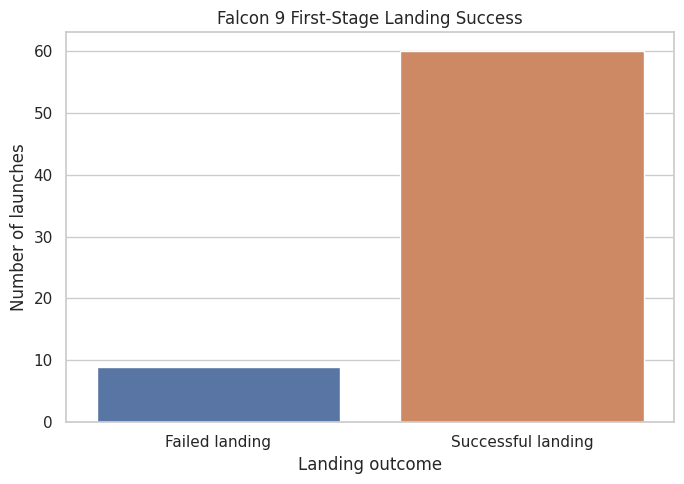

Known landing outcomes:
LandingSuccess
Successful landing    60
Failed landing         9
Name: count, dtype: int64

Success rate among records with known outcomes: 86.96 %


In [10]:

# Separate landing success from landing type
# Outcome strings in this dataset look like "True ASDS" or "False Ocean".

outcome_parts = df["Outcome"].astype(str).str.split()

df["LandingSuccess"] = outcome_parts.str[0].map({
    "True": 1,
    "False": 0
})

df["LandingTypeClean"] = outcome_parts.str[1]

# Exclude records where success is unknown
known = df.dropna(subset=["LandingSuccess"]).copy()
known["LandingSuccess"] = known["LandingSuccess"].astype(int)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))
sns.countplot(
    data=known,
    x="LandingSuccess",
    hue="LandingSuccess",
    legend=False
)
plt.xticks([0, 1], ["Failed landing", "Successful landing"])
plt.title("Falcon 9 First-Stage Landing Success")
plt.xlabel("Landing outcome")
plt.ylabel("Number of launches")
plt.tight_layout()
plt.show()

print("Known landing outcomes:")
print(known["LandingSuccess"].value_counts().rename({
    0: "Failed landing",
    1: "Successful landing"
}))

print(
    "\nSuccess rate among records with known outcomes:",
    round(known["LandingSuccess"].mean() * 100, 2), "%"
)


In [11]:

import sqlite3
import pandas as pd

# Create a database from the capstone dataset
sql_df = df.copy()

# Use readable columns and convert pandas missing values for SQLite
conn = sqlite3.connect(":memory:")
sql_df.to_sql("spacex", conn, index=False, if_exists="replace")

# Query 1: Number of launches at each launch site
query1 = """
SELECT LaunchSite, COUNT(*) AS TotalLaunches
FROM spacex
GROUP BY LaunchSite
ORDER BY TotalLaunches DESC;
"""

print("Query 1: Launches by launch site")
display(pd.read_sql_query(query1, conn))

# Query 2: Average payload mass by orbit
query2 = """
SELECT Orbit,
       ROUND(AVG(PayloadMass), 2) AS AveragePayloadMass
FROM spacex
GROUP BY Orbit
ORDER BY AveragePayloadMass DESC;
"""

print("Query 2: Average payload mass by orbit")
display(pd.read_sql_query(query2, conn))

# Query 3: Successful and failed landing outcomes
query3 = """
SELECT
    CASE
        WHEN LandingSuccess = 1 THEN 'Successful'
        WHEN LandingSuccess = 0 THEN 'Failed'
        ELSE 'Unknown'
    END AS LandingOutcome,
    COUNT(*) AS NumberOfRecords
FROM spacex
GROUP BY LandingOutcome
ORDER BY NumberOfRecords DESC;
"""

print("Query 3: Landing outcome counts")
display(pd.read_sql_query(query3, conn))


Query 1: Launches by launch site


,LaunchSite,TotalLaunches
0,CCAFS SLC 40,55
1,KSC LC 39A,22
2,VAFB SLC 4E,13


Query 2: Average payload mass by orbit


,Orbit,AveragePayloadMass
0,VLEO,15315.71
1,PO,7583.67
2,SO,6104.96
3,GEO,6104.96
4,GTO,5011.99
5,MEO,3987.00
6,LEO,3882.84
7,ISS,3279.94
8,SSO,2060.00
9,ES-L1,570.00


Query 3: Landing outcome counts


,LandingOutcome,NumberOfRecords
0,Successful,41
1,Unknown,19
2,Successful,14
3,Failed,6
4,Successful,5
5,Unknown,2
6,Failed,2
7,Failed,1


In [14]:

import folium

site_coords = {
    "CCAFS SLC 40": (28.561857, -80.577366),
    "KSC LC 39A": (28.608058, -80.603956),
    "VAFB SLC 4E": (34.632093, -120.610829)
}

launch_map = folium.Map(
    location=[32, -100],
    zoom_start=4,
    tiles=None
)

# Try Esri's public World Street Map tiles
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="World Street Map",
    overlay=False,
    control=True
).add_to(launch_map)

for site, coords in site_coords.items():
    count = int((df["LaunchSite"] == site).sum())

    folium.Marker(
        location=coords,
        tooltip=site,
        popup=f"{site}<br>Launch records: {count}"
    ).add_to(launch_map)

folium.LayerControl().add_to(launch_map)
display(launch_map)


In [15]:

!pip -q install dash plotly

import plotly.express as px
from dash import Dash, dcc, html, Input, Output

# Use the prepared dataset
dash_df = df.copy()
dash_df["PayloadMass"] = pd.to_numeric(
    dash_df["PayloadMass"], errors="coerce"
)

app = Dash(__name__)

sites = sorted(dash_df["LaunchSite"].dropna().unique())

app.layout = html.Div([
    html.H1("SpaceX Falcon 9 Launch Analysis"),

    html.Label("Select Launch Site"),
    dcc.Dropdown(
        id="site-dropdown",
        options=[{"label": s, "value": s} for s in sites],
        value=sites[0] if sites else None,
        clearable=False
    ),

    dcc.Graph(id="outcome-chart"),
    dcc.Graph(id="payload-chart")
])

@app.callback(
    Output("outcome-chart", "figure"),
    Output("payload-chart", "figure"),
    Input("site-dropdown", "value")
)
def update_charts(selected_site):
    filtered = dash_df[dash_df["LaunchSite"] == selected_site]

    fig1 = px.histogram(
        filtered,
        x="Outcome",
        title=f"Landing Outcomes — {selected_site}"
    )

    fig2 = px.scatter(
        filtered,
        x="FlightNumber",
        y="PayloadMass",
        color="Outcome",
        title=f"Payload Mass by Flight — {selected_site}"
    )

    return fig1, fig2

print("Dashboard code created successfully.")
print("Next, we'll launch it so you can view the dashboard.")


Dashboard code created successfully.
Next, we'll launch it so you can view the dashboard.


In [16]:

!pip -q install jupyter-dash

from jupyter_dash import JupyterDash
from dash import dcc, html, Input, Output
import plotly.express as px

app = JupyterDash(__name__)

sites = sorted(dash_df["LaunchSite"].dropna().unique())

app.layout = html.Div([
    html.H1("SpaceX Falcon 9 Launch Analysis"),

    html.Label("Select Launch Site"),
    dcc.Dropdown(
        id="site-dropdown",
        options=[{"label": s, "value": s} for s in sites],
        value=sites[0] if sites else None,
        clearable=False
    ),

    dcc.Graph(id="outcome-chart"),
    dcc.Graph(id="payload-chart")
])

@app.callback(
    Output("outcome-chart", "figure"),
    Output("payload-chart", "figure"),
    Input("site-dropdown", "value")
)
def update_charts(selected_site):
    filtered = dash_df[dash_df["LaunchSite"] == selected_site]

    fig1 = px.histogram(
        filtered, x="Outcome",
        title=f"Landing Outcomes — {selected_site}"
    )
    fig2 = px.scatter(
        filtered, x="FlightNumber", y="PayloadMass",
        color="Outcome",
        title=f"Payload Mass by Flight — {selected_site}"
    )
    return fig1, fig2

app.run(mode="inline", port=8050, debug=False)


/usr/local/lib/python3.13/dist-packages/jupyter_dash/jupyter_app.py:103: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

Rows used: 69
Features: ['FlightNumber', 'PayloadMass', 'Flights', 'GridFins', 'Reused', 'Legs', 'Block', 'ReusedCount', 'Longitude', 'Latitude', 'Orbit', 'LaunchSite', 'BoosterVersion', 'Serial']

Target counts:
LandingSuccess
1    60
0     9
Name: count, dtype: int64


,Model,Test Accuracy
1,Random Forest,0.888889
0,Logistic Regression,0.833333
2,Support Vector Machine,0.777778


Best model by test accuracy: Random Forest

Classification report:
              precision    recall  f1-score   support

           0       0.50      0.50      0.50         2
           1       0.94      0.94      0.94        16

    accuracy                           0.89        18
   macro avg       0.72      0.72      0.72        18
weighted avg       0.89      0.89      0.89        18



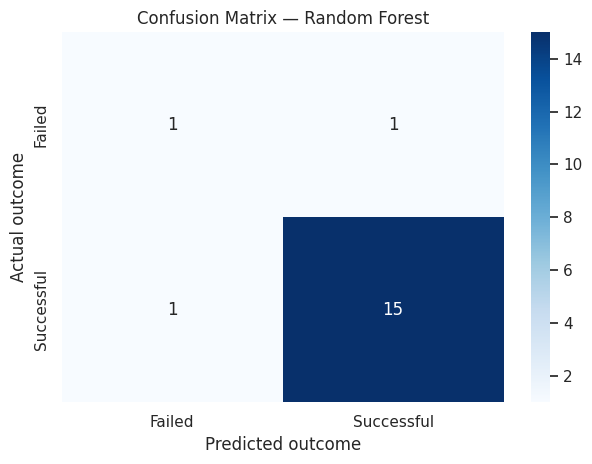

In [17]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Ensure target is numeric and use only known landing outcomes
model_df = df.copy()

if "LandingSuccess" not in model_df.columns:
    parts = model_df["Outcome"].astype(str).str.split()
    model_df["LandingSuccess"] = parts.str[0].map({
        "True": 1,
        "False": 0
    })

model_df["PayloadMass"] = pd.to_numeric(
    model_df["PayloadMass"], errors="coerce"
)
model_df["FlightNumber"] = pd.to_numeric(
    model_df["FlightNumber"], errors="coerce"
)

# Use features available in the IBM capstone dataset
numeric_features = [
    c for c in ["FlightNumber", "PayloadMass", "Flights",
                "GridFins", "Reused", "Legs", "Block",
                "ReusedCount", "Longitude", "Latitude"]
    if c in model_df.columns
]
categorical_features = [
    c for c in ["Orbit", "LaunchSite", "BoosterVersion", "Serial"]
    if c in model_df.columns
]

features = numeric_features + categorical_features
model_df = model_df.dropna(subset=["LandingSuccess"]).copy()
model_df["LandingSuccess"] = model_df["LandingSuccess"].astype(int)
model_df = model_df.dropna(subset=["LandingSuccess"])

X = model_df[features]
y = model_df["LandingSuccess"]

print("Rows used:", len(model_df))
print("Features:", features)
print("\nTarget counts:")
print(y.value_counts())

# Stratify only when both classes have enough examples
stratify_y = y if y.value_counts().min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42,
    stratify=stratify_y
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, class_weight="balanced"
    ),
    "Support Vector Machine": SVC(class_weight="balanced")
}

results = []
fitted_models = {}

for name, classifier in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])
    pipe.fit(X_train, y_train)
    predictions = pipe.predict(X_test)

    score = accuracy_score(y_test, predictions)
    results.append({"Model": name, "Test Accuracy": score})
    fitted_models[name] = pipe

results_df = pd.DataFrame(results).sort_values(
    "Test Accuracy", ascending=False
)

display(results_df)

best_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_name]
y_pred = best_model.predict(X_test)

print("Best model by test accuracy:", best_name)
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Failed", "Successful"],
    yticklabels=["Failed", "Successful"]
)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted outcome")
plt.ylabel("Actual outcome")
plt.tight_layout()
plt.show()


In [18]:

# Export actual model evaluation results
results_df.to_csv("model_comparison.csv", index=False)

from sklearn.metrics import classification_report
import json

report = classification_report(
    y_test, y_pred, output_dict=True, zero_division=0
)

with open("classification_report.json", "w") as f:
    json.dump(report, f, indent=2)

print("Saved model_comparison.csv")
print("Saved classification_report.json")


Saved model_comparison.csv
Saved classification_report.json
